In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nnfs.datasets import spiral_data, vertical_data

x_train, y_train = vertical_data(samples=100, classes=3)

# x_train, y_train = spiral_data(samples=100, classes=3)
print(x_train.shape, y_train.shape)

(300, 2) (300,)


In [8]:
print(x_train[-5:])
print(y_train[-5:])

[[0.85932941 0.50186368]
 [0.70487963 0.40589178]
 [0.75943402 0.45509751]
 [0.48680883 0.62252548]
 [0.55755075 0.49285078]]
[2 2 2 2 2]


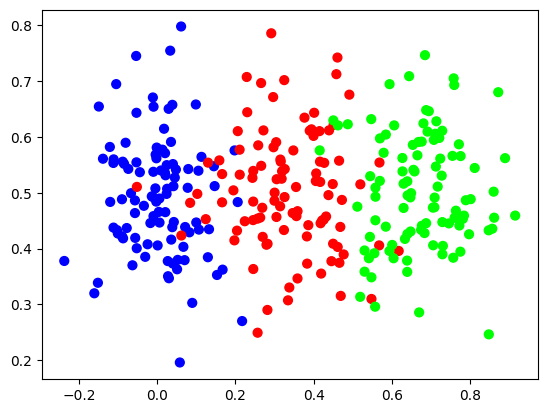

In [13]:
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40, cmap='brg')
plt.show()

In [149]:
print(x_train[:5])
print(y_train[:5])

[[0.04501343 0.33897803]
 [0.19492324 0.56584507]
 [0.03690804 0.47098837]
 [0.20224352 0.55895183]
 [0.0757731  0.57846149]]
[0 0 0 0 0]


In [150]:
class Layer:
    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01*np.random.randn(n_inputs, n_neurons) # 0.1 is a scaling factor for weights to be small. 
        # self.weights = self.weights.T                           #or we can just do (n_inputs, n_neurons) instead of (n_neurons, n_inputs) to eliminate this
        self.biases = np.zeros((1, n_neurons))
        
    def ReLU(self, inputs):
        self.reLUinputs = inputs
        self.output = np.maximum(0, inputs)
    
    def softmax(self, inputs):
        self.exponential_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
        self.output = self.exponential_values / np.sum(self.exponential_values, axis=1, keepdims=True) #axis=1 is for row-wise sum and keepdims=True is to keep the dimensions of the output same as input
    
    def forward(self, inputs):
        self.inputs = inputs
        self.forward_output = np.dot(inputs, self.weights) + self.biases

    def backward(self, dvalues):
        self.dweights = np.dot(self.inputs.T, dvalues)
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
        self.dinputs = np.dot(dvalues, self.weights.T)
    
    def ReLUDerivative(self, dvalues):
        self.dreLU = dvalues.copy()
        self.dreLU[self.reLUinputs <= 0] = 0
    
    def softmaxDerivative(self, dvalues, y_train):
        samples = len(dvalues)

        #removing one hot encoding
        if len(y_train.shape) == 2:
            y_train = np.argmax(y_train, axis=1)
        
        self.dsoftmax = dvalues.copy()
        self.dsoftmax[range(samples), y_train] -= 1

        #normalizing the gradient
        self.dsoftmax = self.dsoftmax / samples

In [151]:
class Loss:
    def calculateLoss(self, output, y):
        sample_losses = self.categoricalClassEntropy(output, y)
        data_loss = np.mean(sample_losses)
        return data_loss

    def categoricalClassEntropy(self, y_pred, y_train):
        samples = len(y_pred)
        y_pred_clipped = np.clip(y_pred, 1e-7, 1-1e-7)

        #len of shape gives the number of dimensions of the array
        if len(y_train.shape) == 1: # scalar values [1, 0, 1] 
            correct_confidences = y_pred_clipped[range(samples), y_train]

        elif len(y_train.shape) == 2: # one-hot encoded [ [0, 1, 0], [1, 0, 0], [0, 1, 0] ]
            correct_confidences = np.sum(y_pred_clipped*y_train, axis=1)

        negative_log_likelihoods = -np.log(correct_confidences)
        return negative_log_likelihoods

    def CrossEntropylossDerivative(self, dvalues, y_train):
        samples = dvalues.shape[0]
        labels = dvalues.shape[1]

        if len(y_train.shape) == 1: # scalar values [1, 0, 1]
            y_train = np.eye(labels)[y_train]
            
        self.dloss = -y_train / dvalues
        self.dloss = self.dinputs / samples #normalizing


In [152]:
def updateParameters(layer, learning_rate):
    # print(layer.dweights)
    layer.weights += -learning_rate * layer.dweights
    layer.biases += -learning_rate * layer.dbiases

In [153]:
learning_rate = 0.25

layer1 = Layer(2, 64)
layer2 = Layer(64, 64)
layer3 = Layer(64, 64)
layer4 = Layer(64, 3)

loss_function = Loss()

epocharr = []
lossarr = []
accarr = []

for epoch in range(5001):

    layer1.forward(x_train)
    layer1.ReLU(layer1.forward_output)

    layer2.forward(layer1.output)
    layer2.ReLU(layer2.forward_output)

    layer3.forward(layer2.output)
    layer3.ReLU(layer3.forward_output)

    layer4.forward(layer1.output)
    layer4.softmax(layer4.forward_output)

    if(epoch % 100 == 0):
        print("Epoch: ", epoch)
        loss = loss_function.calculateLoss(layer4.output, y_train)
        print(f'loss: {loss:.3f}')

        predictions = np.argmax(layer4.output, axis=1)
        if len(y_train.shape) == 2:
            y_train = np.argmax(y_train, axis=1)
        accuracy = np.mean(predictions == y_train)
        print(f'accuracy: {accuracy}')

        epocharr.append(epoch)
        lossarr.append(loss)
        accarr.append(accuracy*100)
    
    
    #backward pass

    layer4.softmaxDerivative(layer4.output, y_train)
    layer4.backward(layer4.dsoftmax)

    layer3.ReLUDerivative(layer4.dinputs)
    layer3.backward(layer3.dreLU)

    layer2.ReLUDerivative(layer3.dinputs)
    layer2.backward(layer2.dreLU)

    layer1.ReLUDerivative(layer4.dinputs)
    layer1.backward(layer1.dreLU)

    updateParameters(layer4, learning_rate)
    updateParameters(layer3, learning_rate)
    updateParameters(layer2, learning_rate)
    updateParameters(layer1, learning_rate)

Epoch:  0
loss: 1.099
accuracy: 0.3333333333333333
Epoch:  100
loss: 0.814
accuracy: 0.72
Epoch:  200
loss: 0.348
accuracy: 0.9366666666666666
Epoch:  300
loss: 0.243
accuracy: 0.9266666666666666
Epoch:  400
loss: 0.210
accuracy: 0.9266666666666666
Epoch:  500
loss: 0.197
accuracy: 0.9266666666666666
Epoch:  600
loss: 0.191
accuracy: 0.9266666666666666
Epoch:  700
loss: 0.187
accuracy: 0.9266666666666666
Epoch:  800
loss: 0.185
accuracy: 0.9266666666666666
Epoch:  900
loss: 0.184
accuracy: 0.9266666666666666
Epoch:  1000
loss: 0.183
accuracy: 0.9266666666666666
Epoch:  1100
loss: 0.183
accuracy: 0.9266666666666666
Epoch:  1200
loss: 0.182
accuracy: 0.9266666666666666
Epoch:  1300
loss: 0.182
accuracy: 0.9266666666666666
Epoch:  1400
loss: 0.182
accuracy: 0.9266666666666666
Epoch:  1500
loss: 0.182
accuracy: 0.9266666666666666
Epoch:  1600
loss: 0.181
accuracy: 0.9266666666666666
Epoch:  1700
loss: 0.181
accuracy: 0.9266666666666666
Epoch:  1800
loss: 0.181
accuracy: 0.93
Epoch:  1900
l

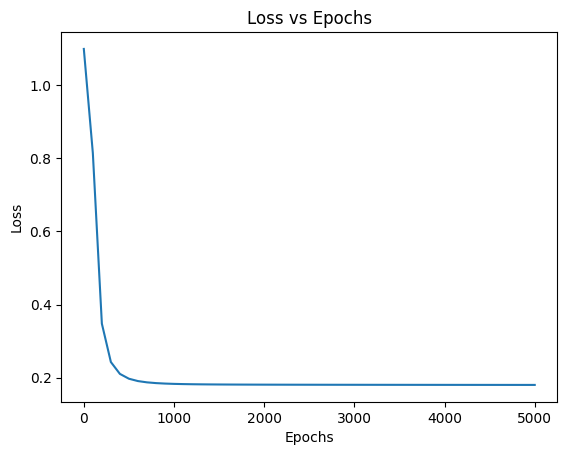

In [154]:
plt.plot(epocharr, lossarr)
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

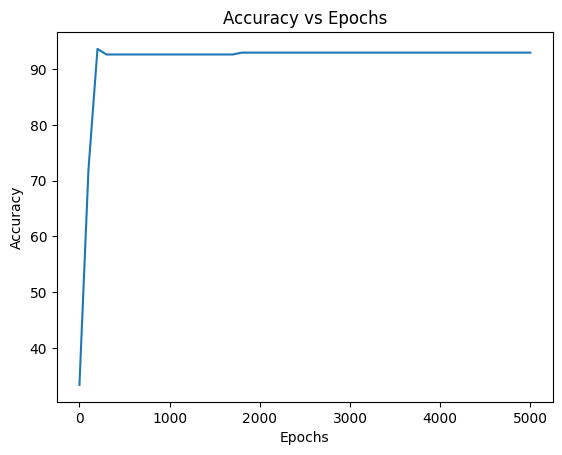

In [155]:
plt.plot(epocharr, accarr)
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()